In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp
from sklearn.decomposition import PCA
from datetime import datetime

import sys
sys.path.append("../../tools")
import prepare as prep
import generation as gr


In [2]:
# ============================================================
# 1. Plot settings
# ============================================================
plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 8,
    'axes.labelsize': 8,
    'axes.titlesize': 9,
    'axes.linewidth': 0.5,
    'legend.fontsize': 7,
    'xtick.major.width': 0.5,
    'ytick.major.width': 0.5,
    'xtick.major.size': 1.5,
    'ytick.major.size': 1.5,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'mathtext.fontset': 'stix',
    'pdf.fonttype': 42,
    'ps.fonttype': 42
})


# ============================================================
# 2. Model
# ============================================================

global NumSpecies,mu,gamma,D,delta

def MultiSpecies(t,y):
    thresh_y = 0
    dydt=np.zeros(NumSpecies)
    s=y
    s[s < thresh_y] = 0
    for i in range(NumSpecies):
        sumy_neg=0
        sumy_pos=0
        for j in range(NumSpecies):
            if gamma[i,j]<0:
                sumy_neg=sumy_neg+gamma[i,j]*s[j]
            if gamma[i,j]>0:
                sumy_pos=sumy_pos+gamma[i,j]*s[j]
        dydt[i]=mu[i]*s[i]*(1+sumy_neg+delta[i]*sumy_pos/(1+sumy_pos))+D[i]
    return dydt


In [38]:
# ============================================================
# 3. Load parameters
# ============================================================
df_compare = pd.read_pickle("efficient_N1.pkl")

sample_number = 1

NumSpecies = 10
MaxNum = 20
featgam = NumSpecies**2 - NumSpecies

Xnum_pad = df_compare["initial_X"].iloc[sample_number].reshape(1, -1)
#Xnum_pad = df_compare["final_X"].iloc[sample_number].reshape(1, -1)
Xnum = prep.recovery_Xnum(Xnum_pad, NumSpecies, MaxNum)


Total initializations: 100
Stable initializations: 100
Number of identified stable states: 7
Stable state 1: 43 initializations
Stable state 2: 15 initializations
Stable state 3: 19 initializations
Stable state 4: 4 initializations
Stable state 5: 6 initializations
Stable state 6: 2 initializations
Stable state 7: 11 initializations

Explained variance ratio:
[0.41624943 0.2276666 ]
Cumulative explained variance: 0.6439160342510593


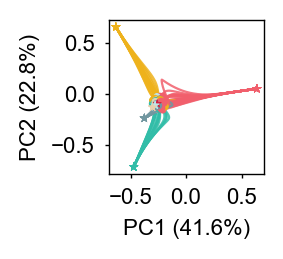

In [39]:
wer = 0

# mu
mu = Xnum[wer, 0:NumSpecies]

# gamma matrix
gamma = np.zeros((NumSpecies, NumSpecies))

indext = NumSpecies

for i in range(NumSpecies):
    for j in range(NumSpecies):
        if i == j:
            gamma[i, j] = -1
        else:
            gamma[i, j] = Xnum[wer, indext]
            indext += 1

# D
D = Xnum[wer, NumSpecies + featgam: NumSpecies + featgam + NumSpecies]

delta = 0.2 * np.ones(NumSpecies)

# ============================================================
# 4. Simulate multiple initializations
# ============================================================

timespan = np.arange(0, 800.1, 0.1)
n_initializations = 100
np.random.seed(42)
trajectory_list = []

for repeat in range(n_initializations):

    # Generate a new initial condition
    initial = np.random.rand(NumSpecies)/NumSpecies

    sol = solve_ivp(MultiSpecies, [0, max(timespan)], initial, method='RK45', t_eval=timespan, rtol=1e-6, atol=1e-9)

    if not sol.success:
        print(f"Initialization {repeat + 1} failed.")
        continue

    # Shape: (n_timepoints, NumSpecies)
    y = sol.y.T

    # Remove negative numerical values
    y[y < 0] = 0

    # Save the trajectory
    trajectory_list.append(y)

from scipy.cluster.hierarchy import linkage, fcluster
from sklearn.decomposition import PCA
from matplotlib.colors import to_hex


# ============================================================
# 5. Identify steady-state initializations
# ============================================================

# Keep the same sampling interval as the original analysis.
# Original sampling interval: every 20 integration steps.
sampling_interval = 20

stable_trajectory_list = []
stable_final_states = []

for trajectory in trajectory_list:

    # Reverse chronological order and downsample
    # This reproduces the original abundance sampling procedure.
    sampled_y = trajectory[::-sampling_interval, :]

    final_state = np.zeros(NumSpecies)
    all_species_stable = True

    for spc in range(NumSpecies):

        result = gr.classify_abundance(sampled_y[:, spc])

        if result[0] != 0:
            all_species_stable = False
            break

        final_state[spc] = result[1]

    # Keep only initializations where all species are steady
    if all_species_stable:

        stable_trajectory_list.append(trajectory)
        stable_final_states.append(final_state)

stable_final_states = np.array(stable_final_states)

n_stable_init = len(stable_trajectory_list)

print(f"Total initializations: {len(trajectory_list)}")
print(f"Stable initializations: {n_stable_init}")


# ============================================================
# 6. Cluster using the original Calculate_Index method
# ============================================================

if n_stable_init == 0:
    raise ValueError("No stable initializations were identified.")

cluster_threshold = 0.1

cluster_labels = gr.Calculate_Index(
    n_stable_init,
    stable_final_states,
    cluster_threshold
).astype(int)

n_clusters = int(np.max(cluster_labels))

print(f"Number of identified stable states: {n_clusters}")

for cluster_id in range(1, n_clusters + 1):

    indices = np.where(cluster_labels == cluster_id)[0]
    print(f"Stable state {cluster_id}: {len(indices)} initializations")

# ============================================================
# 7. Perform PCA on all stable trajectories
# ============================================================

all_states = np.concatenate(stable_trajectory_list, axis=0)

pca = PCA(n_components=2)

all_states_pca = pca.fit_transform(all_states)

print("\nExplained variance ratio:")
print(pca.explained_variance_ratio_)
print("Cumulative explained variance:", np.sum(pca.explained_variance_ratio_))

# Recover individual trajectories
n_timepoints = len(timespan)

trajectory_pca_list = []

for i in range(n_stable_init):

    start = i * n_timepoints
    end = (i + 1) * n_timepoints

    trajectory_pca_list.append(all_states_pca[start:end])


# ============================================================
# 8. Plot PCA trajectories using the original color palette
# ============================================================

colors = [
    '#F15F6C','#32BDA8','#EEB21C','#BFE5E8','#E8D0AE',
    '#D61F3E','#7297A0','#567589','#3E516F', 
]

# colors = [
#     '#BFE5E8', '#8CA06B', '#32BDA8', '#7297A0', 
#     '#567589', '#F15F6C', '#D61F3E', '#E8D0AE',
#     '#3E516F', '#EEB21C'
# ]

cluster_colors = {
    cluster_id: colors[(cluster_id - 1) % len(colors)]
    for cluster_id in range(1, n_clusters + 1)
}

fig, ax = plt.subplots(figsize=(1,1), dpi=200)

for i, trajectory_pca in enumerate(trajectory_pca_list):

    cluster_id = cluster_labels[i]
    color = cluster_colors[cluster_id]

    # Trajectory
    ax.plot(
        trajectory_pca[:, 0],
        trajectory_pca[:, 1],
        '-',
        linewidth=0.8,
        color=color,
        alpha=0.85
    )

    # Initial state
    ax.scatter(
        trajectory_pca[0, 0],
        trajectory_pca[0, 1],
        s=8,
        color=color,
        edgecolors='none',
        zorder=3
    )

    # Final state
    ax.scatter(
        trajectory_pca[-1, 0],
        trajectory_pca[-1, 1],
        s=12,
        color=color,
        marker='*',
        edgecolors='none',
        zorder=4
    )


ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}%)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}%)")

ax.tick_params(
    axis='both',
    which='both',
    direction='out'
)

plt.savefig(
    f"PCA_trajectories_clustered_"
    f"{datetime.now().strftime('%Y%m%d_%H%M%S')}.pdf",
    dpi=1000,
    bbox_inches='tight',
    transparent=True
)

plt.show()
